# VisSalFormer on SalChartQA

We compare two ways to load and run VisSalFormer:

1. **Our implementation:** `load_predictor('vissalformer')`.
2. **Authors' model:** `SalFormer` loaded directly from `official_reference/model_swin.py`, following their evaluation script.

Both use the same published weights, official tensors, question tokens, batch order and metric calculations. Our network code is a copy of theirs. We check whether our implementation reproduces the authors' model.

We also prepare image tensors from our PNG files. Both input paths use the same question tokenization, padding, batch order and official reference maps.

We compare KL, CC and NSS with Table 2 of Wang et al. (CHI 2024). Run the cells from top to bottom. The weights and encoder files must already be available locally.


## 1. Set up the notebook

Use the local model cache and load the project and official helper modules.


In [1]:
import hashlib
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault('HF_HUB_OFFLINE', '1')
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
warnings.filterwarnings('ignore', message='IProgress not found')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader

ROOT = Path.cwd().resolve()
while not (ROOT / 'models/__init__.py').is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Run this notebook from the GazePrediction project.')
    ROOT = ROOT.parent
EXPERIMENT = ROOT / 'reproductions/vissalformer_salchartqa'
REFERENCE = EXPERIMENT / 'official_reference'
OFFICIAL_DATA = EXPERIMENT / 'data/official'
PROVIDED_DATA = EXPERIMENT / 'data/provided'
sys.path[:0] = [str(ROOT), str(REFERENCE)]

from common.dataset import ChartDataset
from models import load_predictor
from models.vissalformer import IMAGE_MEAN, IMAGE_STD, VISSALFORMER_DIR, preprocess_image
from dataset_new import ImagesWithSaliency
from tokenizer_bert import padding_fn

bert-base-uncased tokenizer loaded


### Settings

Keep the official batch size of 16. Use a GPU when available; otherwise use the CPU.


In [2]:
BATCH_SIZE = 16
EPS = 1e-10
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PUBLISHED_SCORES = {'NSS': 1.782, 'CC': 0.674, 'KL': 0.532}

### Display and file helpers

These helpers check file hashes and show tensor details in tables.


In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def describe(variable, value, description):
    """Show the shape, type and range of a tensor or array."""
    array = value.detach().cpu().numpy() if torch.is_tensor(value) else np.asarray(value)
    return {'Variable': variable, 'Shape': ' × '.join(map(str, array.shape)),
            'Type': str(value.dtype).replace('torch.', ''),
            'Range': f'[{array.min():.4g}, {array.max():.4g}]', 'Description': description}


def table(rows, index):
    with pd.option_context('display.max_colwidth', None):
        display(pd.DataFrame(rows).set_index(index))

## 2. Published results

Wang, Y., Wang, W., Abdelhafez, A., Elfares, M., Hu, Z., Bâce, M. and Bulling, A. (2024). *SalChartQA: Question-driven Saliency on Information Visualisations*. CHI '24. https://doi.org/10.1145/3613904.3642942

The reference values come from Table 2, row “VisSalFormer (Ours)”, trained on SalChartQA. This notebook calculates KL, CC and NSS, following the authors' evaluation script. NSS uses fixation maps. CC and KL use saliency maps.

### What each metric means

| Metric | Full name | What it measures | Better score |
|---|---|---|---|
| KL | Kullback–Leibler divergence | How much the predicted saliency distribution differs from the reference distribution. A score of 0 means they match. | Lower |
| CC | Pearson correlation coefficient | Whether the predicted and reference saliency maps rise and fall together across pixels. A score of 1 means perfect positive correlation. | Higher |
| NSS | Normalized Scanpath Saliency | The average standardized prediction at fixation points. Positive values mean these points receive more saliency than the map average. | Higher |


In [4]:
published_results = pd.DataFrame({
    'Published score': PUBLISHED_SCORES,
    'Better score': {'NSS': 'Higher', 'CC': 'Higher', 'KL': 'Lower'},
})
published_results.index.name = 'Metric'
display(published_results)

,Published score,Better score
Metric,,
NSS,1.782,Higher
CC,0.674,Higher
KL,0.532,Lower


## 3. Load data

We use the authors' test split: 291 charts, with two questions per chart (582 examples). The paper uses a random 7:2:1 train/validation/test split. Reference saliency maps come from BubbleView clicks smoothed with a Gaussian kernel (σ = 19 px).

### 3.1 Load the official data

Source: `data/official/test.npy`. We use the authors' `ImagesWithSaliency` loader from `official_reference/dataset_new.py`.

Each example contains a prepared image tensor, question, fixation map, saliency map and name. The archive and paper in this folder are not needed by the loader.


In [5]:
test_set = ImagesWithSaliency(str(OFFICIAL_DATA / 'test.npy'))
names = [Path(item[4]).stem for item in test_set]

print('Official test examples:', len(test_set))

Official test examples: 582


### Inspect one official example


In [6]:
image, question, fixations, saliency, name = test_set[0]
table([describe('image', image, 'RGB image at 224 × 224, normalized with the SalChartQA mean and standard deviation'),
       {'Variable': 'question', 'Shape': '—', 'Type': 'str', 'Range': '—', 'Description': f'Question text, for example «{question}»'},
       describe('fixations', fixations, 'Binary BubbleView click map (1 = click); used for NSS'),
       describe('saliency', saliency, 'Reference saliency map (smoothed clicks); used for KL and CC'),
       {'Variable': 'name', 'Shape': '—', 'Type': 'str', 'Range': '—', 'Description': f'Example ID, for example {name}'}],
      'Variable')

,Shape,Type,Range,Description
Variable,,,,
image,3 × 224 × 224,float32,"[-3.803, 0.5054]","RGB image at 224 × 224, normalized with the SalChartQA mean and standard deviation"
question,—,str,—,"Question text, for example «what's the name of the biggest section in the U.S. bar?»"
fixations,1 × 128 × 128,uint8,"[0, 1]",Binary BubbleView click map (1 = click); used for NSS
saliency,1 × 128 × 128,float32,"[0, 0.9961]",Reference saliency map (smoothed clicks); used for KL and CC
name,—,str,—,"Example ID, for example 1878_Q0.png"


### 3.2 Load the data provided by us

We adapt the official test for our PNG input path. The images and questions belong to SalChartQA; we provide the file layout and task table.

#### Where the images come from

The authors describe `raw_img/` in the original SalChartQA dataset as the original chart images from **ChartQA**. The dataset is available through the [authors' data release](https://doi.org/10.18419/darus-3884). See also the local [official README](official_reference/README.md).

We use the example names in `test.npy` to identify the charts needed for this experiment. For example:

```text
test.npy example name: 1878_Q0.png
condition ID:          1878_Q0
chart ID:              1878
image to match:        1878.png
local image path:      data/provided/salchartqa_images/charts/1878.png
```

#### How each local file is built

| Local file | Source | Preparation |
|---|---|---|
| `salchartqa_images/charts/<chart_id>.png` | Original chart images from SalChartQA (`raw_img/`, originally from ChartQA) | Select the images matching the chart IDs in the official test. Keep one PNG per chart. |
| `salchartqa_images/tasks.csv` | Example names and question text in `test.npy` | Create one row per example: `cond_id` is the name without `.png`; `chart_id` removes the final question suffix; `question` keeps the official question text. Keep the official example order. |

We checked that all 582 task rows match the official names and questions in order and that the 291 referenced PNG files are present. The original `raw_img/` archive is not stored here for a byte-by-byte source comparison.

#### Load the prepared files

We read `tasks.csv` with pandas. Our `ChartDataset` class finds each image in `charts/`. The evaluation keeps the order of `test.npy` directly. The reference fixation and saliency maps also come from `test.npy`.


In [7]:
image_folder = PROVIDED_DATA / 'salchartqa_images'
tasks = pd.read_csv(image_folder / 'tasks.csv', dtype=str, keep_default_na=False)
images = ChartDataset('salchartqa', image_folder, tasks)
chart_of = tasks.set_index('cond_id').chart_id

print('Provided test examples:', len(tasks))
print('Provided charts:', tasks.chart_id.nunique())
display(tasks.head())

Provided test examples: 582
Provided charts: 291


,cond_id,chart_id,question
0,1878_Q0,1878,what's the name of the biggest section in the ...
1,1878_Q1,1878,What's the average of U.S. and Germany Agree s...
2,4353_Q0,4353,The sum % of all Republicans and Democrats who...
3,4353_Q1,4353,What % of voters think any voter should have t...
4,6874_Q0,6874,What's the percentage of respondents who think...


### 3.3 Check that both inputs match

Check that both sources contain the same question IDs and that the official test has no duplicate IDs. The evaluation keeps the order from the official data.


In [8]:
assert len(set(names)) == len(names), 'The official test has duplicate IDs.'
assert sorted(names) == sorted(tasks.cond_id), 'The two sources have different example IDs.'

print('Both inputs contain the same test examples.')

Both inputs contain the same test examples.


### Check the image inputs

We prepare each PNG with `preprocess_image` and compare it with the image tensor in `test.npy`. This check covers all 582 examples.


In [9]:
recomputed = {}
identical = 0
for image, question, fixations, saliency, name in test_set:
    chart = chart_of[Path(name).stem]
    if chart not in recomputed:
        recomputed[chart] = preprocess_image(images.image(chart))[0]
    identical += int(torch.equal(recomputed[chart], image))
print(f'Image tensors matching the PNG inputs: {identical} of {len(test_set)}')

Image tensors matching the PNG inputs: 582 of 582


## 4. Load the two models

Both models load the authors' published checkpoint.

### 4.1 Our implementation


In [10]:
predictor = load_predictor('vissalformer')
predictor.network.to(DEVICE).eval()
network = predictor.network
checkpoint = VISSALFORMER_DIR / 'VisSalFormer_weights.tar'
network_code = VISSALFORMER_DIR / 'salformer.py'
assert sha256(network_code) == sha256(REFERENCE / 'model_swin.py')
parameter = next(network.parameters())

table([
    {'Setting': 'Weights', 'Value': f'{checkpoint.name} ({checkpoint.stat().st_size / 1e9:.2f} GB)', 'Description': 'Checkpoint published by the authors'},
    {'Setting': 'Weights SHA-256', 'Value': sha256(checkpoint), 'Description': 'Identifies the checkpoint used here'},
    {'Setting': 'Network code', 'Value': 'model_swin.py', 'Description': f'SHA-256 {sha256(network_code)[:16]}…, matches the official file'},
    {'Setting': 'Image encoder', 'Value': predictor.image_model, 'Description': 'Swin-T; 7 × 7 = 49 tokens with 768 values each'},
    {'Setting': 'Text encoder', 'Value': predictor.text_model, 'Description': 'BERT base; runs without gradients in the forward pass'},
    {'Setting': 'Text queries', 'Value': ' × '.join(map(str, network.text_feature_query.shape)), 'Description': 'Learned vectors that summarize the question using cross-attention'},
    {'Setting': 'Tokenizer', 'Value': type(predictor.tokenizer).__name__, 'Description': 'bert-base-uncased tokenizer'},
    {'Setting': 'Image normalization', 'Value': f'mean {IMAGE_MEAN}, standard deviation {IMAGE_STD}', 'Description': 'SalChartQA values for each RGB channel'},
    {'Setting': 'Parameters', 'Value': f'{sum(p.numel() for p in network.parameters()):,}', 'Description': 'Total network parameters, including Swin-T and BERT'},
    {'Setting': 'Device and precision', 'Value': f'{parameter.device.type}, {str(parameter.dtype).replace("torch.", "")}', 'Description': 'Evaluation mode, without gradients'},
    {'Setting': 'Batch size', 'Value': BATCH_SIZE, 'Description': 'Default in the official script (evaluation.py)'},
], 'Setting')

,Value,Description
Setting,,
Weights,VisSalFormer_weights.tar (1.86 GB),Checkpoint published by the authors
Weights SHA-256,c08b19bae5b10b18566a4c2793e5df74bc28495e8d85986a6e211dc268ba8db5,Identifies the checkpoint used here
Network code,model_swin.py,"SHA-256 19de51c19ed98356…, matches the official file"
Image encoder,microsoft/swin-tiny-patch4-window7-224,Swin-T; 7 × 7 = 49 tokens with 768 values each
Text encoder,bert-base-uncased,BERT base; runs without gradients in the forward pass
Text queries,1 × 10 × 768,Learned vectors that summarize the question using cross-attention
Tokenizer,BertTokenizerFast,bert-base-uncased tokenizer
Image normalization,"mean (0.8801, 0.8827, 0.884), standard deviation (0.2523, 0.2321, 0.24)",SalChartQA values for each RGB channel
Parameters,"155,214,333","Total network parameters, including Swin-T and BERT"


#### How we turn an input image into a tensor

Our image preparation is in `models/vissalformer/model.py`, in `preprocess_image`. We use it below on the first provided PNG:

1. Read the chart as RGB and convert its pixels to `float32`.
2. Change the layout from `[height, width, channels]` to `[channels, height, width]` and divide by 255.
3. Add a batch dimension and resize to 224 × 224 with bilinear interpolation and antialiasing.
4. Normalize each RGB channel with `(pixel - mean) / std`.

The means are `(0.8801, 0.8827, 0.8840)` and the standard deviations are `(0.2523, 0.2321, 0.2400)`.

The authors' evaluation does not read PNG files: it loads image tensors already prepared in `test.npy`.

**Source of the normalization constants:** The copied official evaluation code loads already prepared tensors and does not define these constants or document how they were originally calculated. We verified that these values reproduce all 582 official test image tensors exactly. They can also be recovered from the affine relationship between a resized PNG and its official tensor. This confirms the input transformation, but does not establish which dataset split or calculation the authors used to obtain the constants.


In [11]:
from PIL import Image

example_id = names[0]
example_chart = chart_of[example_id]
example_question = test_set[0][1]
example_path = images.image(example_chart)

# Prepare the exact image tensor used by our implementation.
pixel_values = preprocess_image(example_path)

# Read the source RGB image for inspection.
with Image.open(example_path) as source:
    original = np.array(source.convert('RGB'))

print('Source image:', example_path)
print('Prepared tensor shape:', tuple(pixel_values.shape))

Source image: /Users/luisavillanueva/Documents/Lab/GazePrediction/reproductions/vissalformer_salchartqa/data/provided/salchartqa_images/charts/1878.png
Prepared tensor shape: (1, 3, 224, 224)


#### Prepare PNG batches with the same question tokens

For each official batch, read the corresponding PNG files and questions from our task table. Pass them through the authors' `padding_fn` in the same order. This gives the same BERT tokens and padding as the official batch.

Check that both the image tensors and all question token tensors match. Only the source of the image changes: PNG files instead of prepared images in `test.npy`.


In [12]:
question_of = tasks.set_index('cond_id').question


def prepare_png_batch(official_batch):
    _, official_text, fixations, saliency, batch_names = official_batch
    examples = []
    for index, name in enumerate(batch_names):
        condition_id = Path(name).stem
        image_tensor = preprocess_image(images.image(chart_of[condition_id]))[0]
        question = question_of[condition_id]
        examples.append((image_tensor, question, fixations[index], saliency[index], name))

    png_batch = padding_fn(examples)
    assert torch.equal(png_batch[0], official_batch[0]), 'Image tensors differ.'
    for key in official_text:
        assert torch.equal(png_batch[1][key], official_text[key]), f'Question tokens differ: {key}'
    return png_batch

### 4.2 Authors' model

Load `SalFormer` directly from the official file. Use the encoder names written in the BERT branch of `official_reference/evaluation.py`: `microsoft/swin-tiny-patch4-window7-224` and `bert-base-uncased`.

Create fresh encoders and load the authors' published checkpoint. This model does not read encoder settings or weights from our `predictor`.


In [13]:
from model_swin import SalFormer as OfficialSalFormer
from transformers import BertModel, SwinModel


official_model = OfficialSalFormer(
    SwinModel.from_pretrained('microsoft/swin-tiny-patch4-window7-224'),
    BertModel.from_pretrained('bert-base-uncased'),
)
official_checkpoint_path = ROOT / 'external/vissalformer/VisSalFormer_weights.tar'
official_checkpoint = torch.load(official_checkpoint_path, map_location='cpu')
official_model.load_state_dict(official_checkpoint['model_state_dict'])
del official_checkpoint
official_model.to(DEVICE).eval()

print("Authors' model loaded from:", REFERENCE / 'model_swin.py')

Authors' model loaded from: /Users/luisavillanueva/Documents/Lab/GazePrediction/reproductions/vissalformer_salchartqa/official_reference/model_swin.py


### 4.3 Check both models on one batch

Use the same image tensors and padded question tokens. Compare their raw outputs before evaluating the full test.


In [14]:
check_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=padding_fn, num_workers=0)
check_images, check_text, _, _, _ = next(iter(check_loader))
check_images = check_images.to(DEVICE)
check_text = {key: value.to(DEVICE) for key, value in check_text.items()}

with torch.no_grad():
    our_output = network(check_images, check_text)
    official_output = official_model(check_images, check_text)

max_difference = (our_output - official_output).abs().max().item()
print('Largest output difference on the first batch:', max_difference)
assert torch.allclose(our_output, official_output, rtol=1e-5, atol=1e-6), 'The model outputs differ.'
del our_output, official_output, check_images, check_text

Largest output difference on the first batch: 0.0


## 5. Inspect the model inputs

We inspect the image tensor and question tokens separately.

### 5.1 Inspect the image tensor

`pixel_values` has shape `[1, 3, 224, 224]`: one image, three RGB channels, height and width. Its type is `float32`.

The values below are the actual model input, without reversing normalization or changing them for display. Negative values are expected. PyTorch shortens the printed tensor with `...`. We also show the three values at the top-left pixel.

For the authors' model, the official image tensor is loaded directly from `test.npy`. We compare it with the tensor prepared from our PNG.


In [15]:
official_tensor = test_set[0][0].unsqueeze(0)

table([
    describe('Our PNG tensor', pixel_values, 'Created by preprocess_image'),
    describe('Official tensor', official_tensor, 'Loaded from test.npy'),
], 'Variable')
print('Our image tensor:')
print(pixel_values)
print('Top-left pixel [R, G, B]:', pixel_values[0, :, 0, 0])
print('Exactly equal to the official image tensor:', torch.equal(pixel_values, official_tensor))

,Shape,Type,Range,Description
Variable,,,,
Our PNG tensor,1 × 3 × 224 × 224,float32,"[-3.803, 0.5054]",Created by preprocess_image
Official tensor,1 × 3 × 224 × 224,float32,"[-3.803, 0.5054]",Loaded from test.npy


Our image tensor:
tensor([[[[ 0.4752,  0.4752,  0.4752,  ...,  0.4752,  0.4752,  0.4752],
          [ 0.4752, -0.3384, -0.9781,  ..., -0.9781, -0.9559, -0.0143],
          [ 0.4752, -0.1412, -0.6258,  ..., -0.6258, -0.6090,  0.1044],
          ...,
          [ 0.4752, -0.7247, -1.6680,  ..., -1.6680, -1.6353, -0.2467],
          [ 0.4752,  0.4136,  0.3651,  ...,  0.3651,  0.3668,  0.4381],
          [ 0.4752,  0.4752,  0.4752,  ...,  0.4752,  0.4752,  0.4752]],

         [[ 0.5054,  0.5054,  0.5054,  ...,  0.5054,  0.5054,  0.5054],
          [ 0.5054, -0.3791, -1.0744,  ..., -1.0744, -1.0503, -0.0267],
          [ 0.5054, -0.1647, -0.6914,  ..., -0.6914, -0.6732,  0.1023],
          ...,
          [ 0.5054, -0.7990, -1.8244,  ..., -1.8244, -1.7888, -0.2793],
          [ 0.5054,  0.4384,  0.3857,  ...,  0.3857,  0.3875,  0.4651],
          [ 0.5054,  0.5054,  0.5054,  ...,  0.5054,  0.5054,  0.5054]],

         [[ 0.4833,  0.4833,  0.4833,  ...,  0.4833,  0.4833,  0.4833],
          [ 

### 5.2 Inspect the question tokens

Build the first PNG batch with the same question order and `padding_fn` as the official input. The helper checks that `input_ids`, `token_type_ids` and `attention_mask` match exactly.

Show the first question below, including its batch padding. Both input paths now pass these same tokens to the model.


In [16]:
official_input_batch = next(iter(check_loader))
png_input_batch = prepare_png_batch(official_input_batch)
text_inputs = {key: value[:1] for key, value in png_input_batch[1].items()}

descriptions = {
    'input_ids': 'Question token IDs, including special tokens and batch padding',
    'token_type_ids': 'Token segment IDs (one sentence: all 0)',
    'attention_mask': 'Valid tokens (1) and padding tokens (0)',
}
rows = [describe(key, value, descriptions[key]) for key, value in text_inputs.items()]
table(rows, 'Variable')
print('Question:', example_question)
print('Tokens:', ' '.join(predictor.tokenizer.convert_ids_to_tokens(text_inputs['input_ids'][0])))
print('Image and question tensors match the official batch exactly.')

,Shape,Type,Range,Description
Variable,,,,
input_ids,1 × 29,int64,"[0, 5221]","Question token IDs, including special tokens and batch padding"
token_type_ids,1 × 29,int64,"[0, 0]",Token segment IDs (one sentence: all 0)
attention_mask,1 × 29,int64,"[0, 1]",Valid tokens (1) and padding tokens (0)


Question: what's the name of the biggest section in the U.S. bar?
Tokens: [CLS] what ' s the name of the biggest section in the u . s . bar ? [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
Image and question tensors match the official batch exactly.


### 5.3 Inspect the model output

The network returns a `float32` tensor with shape `[batch_size, 1, 128, 128]`: one saliency map for each image–question pair. For a batch of 16 examples, this is `[16, 1, 128, 128]`.

The final sigmoid gives scores between 0 and 1. A higher value means the model assigns more saliency to that location. These scores do not have to sum to 1, and the output contains no predicted answer or gaze sequence.

Below we show the raw output tensor for the first example and its top-left 5 × 5 values. The heatmaps in section 6 display these same raw values using colors; no resizing or probability normalization is applied.


In [17]:
output_batch = next(iter(check_loader))
output_images, output_text, _, _, output_names = output_batch

with torch.no_grad():
    output_tensor = network(
        output_images.to(DEVICE),
        {key: value.to(DEVICE) for key, value in output_text.items()},
    )

first_output = output_tensor[:1]
table([
    describe('Batch output', output_tensor, 'One saliency map per image and question'),
    describe('First example output', first_output, 'Raw sigmoid scores, without resizing or normalization'),
], 'Variable')
print('Example:', output_names[0])
print('Raw output tensor (PyTorch shortens the display with ...):')
print(first_output)
print('Top-left 5 × 5 values:')
print(first_output[0, 0, :5, :5])
print('Sum of scores:', first_output.sum().item())

,Shape,Type,Range,Description
Variable,,,,
Batch output,16 × 1 × 128 × 128,float32,"[0.008566, 1]",One saliency map per image and question
First example output,1 × 1 × 128 × 128,float32,"[0.02855, 1]","Raw sigmoid scores, without resizing or normalization"


Example: 1878_Q0.png
Raw output tensor (PyTorch shortens the display with ...):
tensor([[[[0.0470, 0.0475, 0.0472,  ..., 0.0512, 0.0506, 0.0514],
          [0.0449, 0.0453, 0.0449,  ..., 0.0504, 0.0498, 0.0506],
          [0.0480, 0.0483, 0.0480,  ..., 0.0530, 0.0524, 0.0532],
          ...,
          [0.0308, 0.0314, 0.0305,  ..., 0.0409, 0.0400, 0.0409],
          [0.0291, 0.0296, 0.0288,  ..., 0.0404, 0.0395, 0.0402],
          [0.0305, 0.0311, 0.0303,  ..., 0.0421, 0.0412, 0.0417]]]])
Top-left 5 × 5 values:
tensor([[0.0470, 0.0475, 0.0472, 0.0471, 0.0471],
        [0.0449, 0.0453, 0.0449, 0.0448, 0.0446],
        [0.0480, 0.0483, 0.0480, 0.0479, 0.0477],
        [0.0484, 0.0486, 0.0484, 0.0481, 0.0479],
        [0.0489, 0.0490, 0.0487, 0.0484, 0.0481]])
Sum of scores: 2775.23583984375


## 6. Compare predictions for 10 different charts


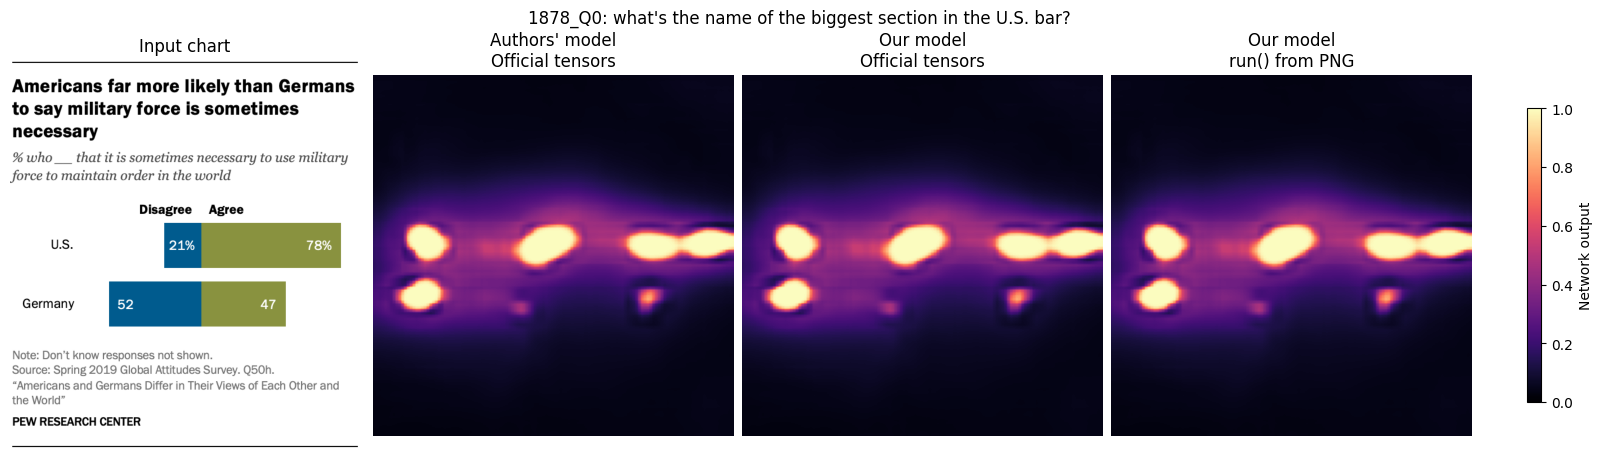

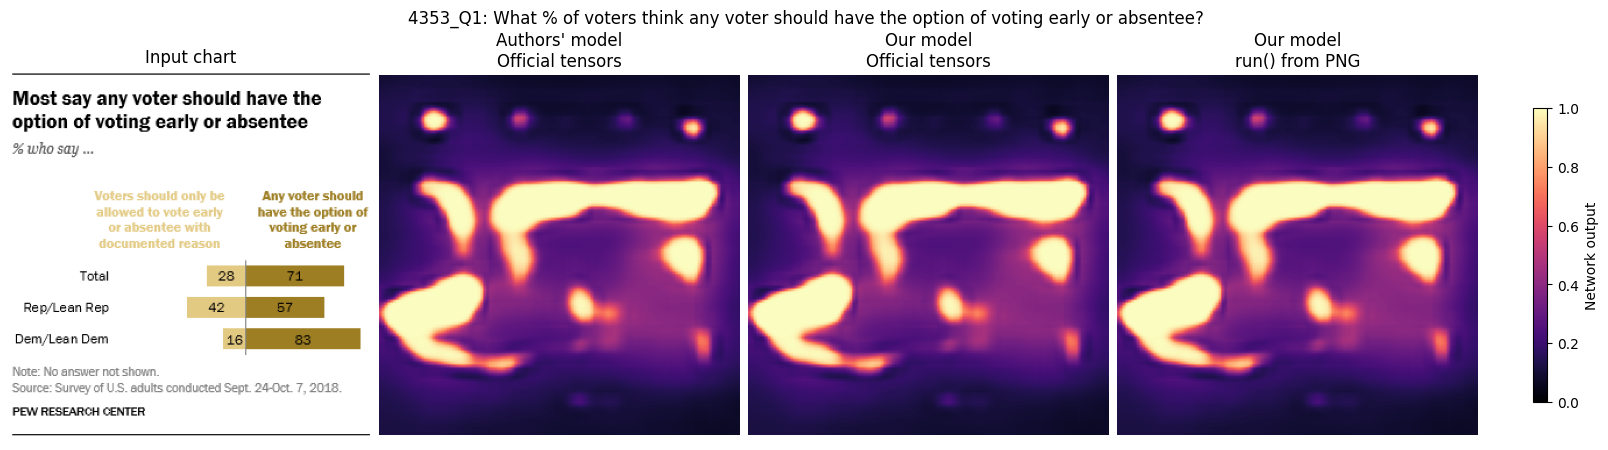

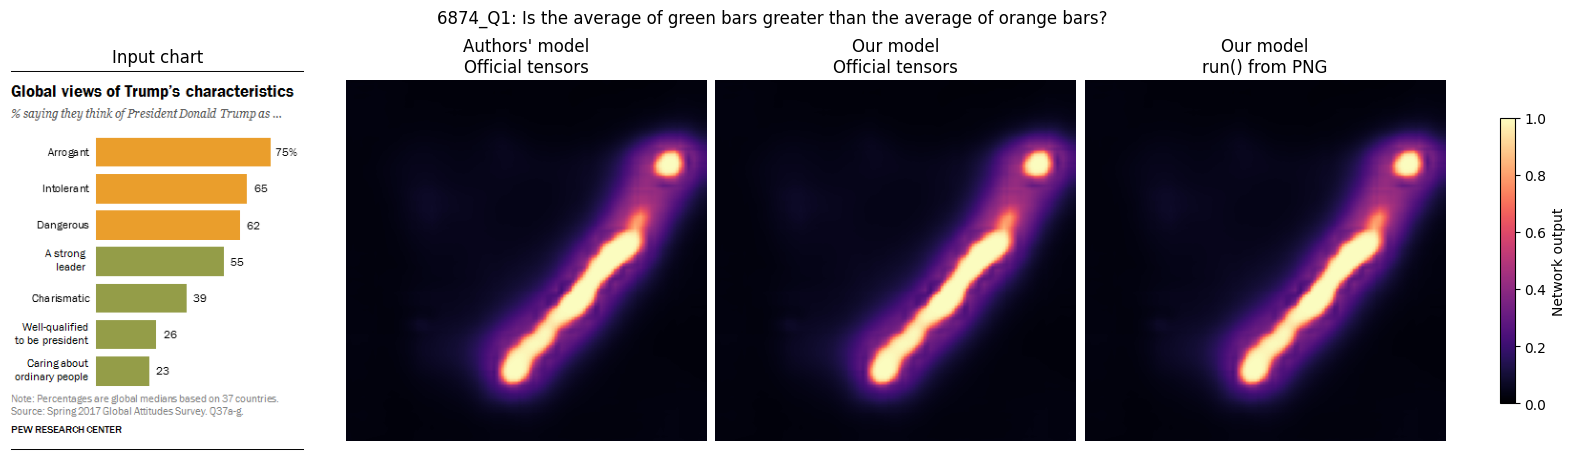

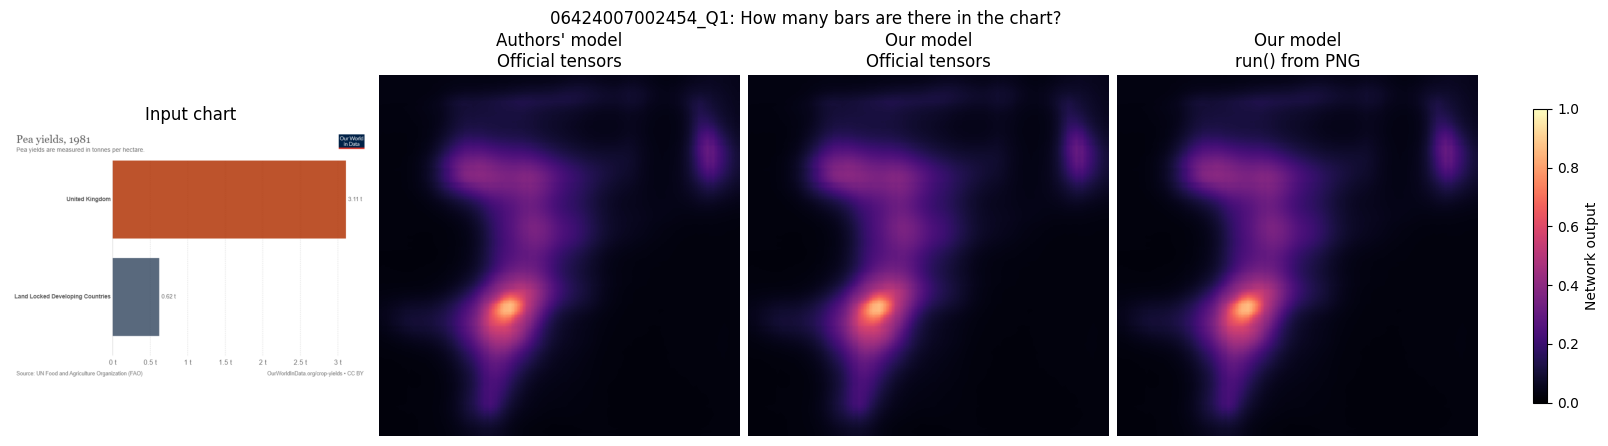

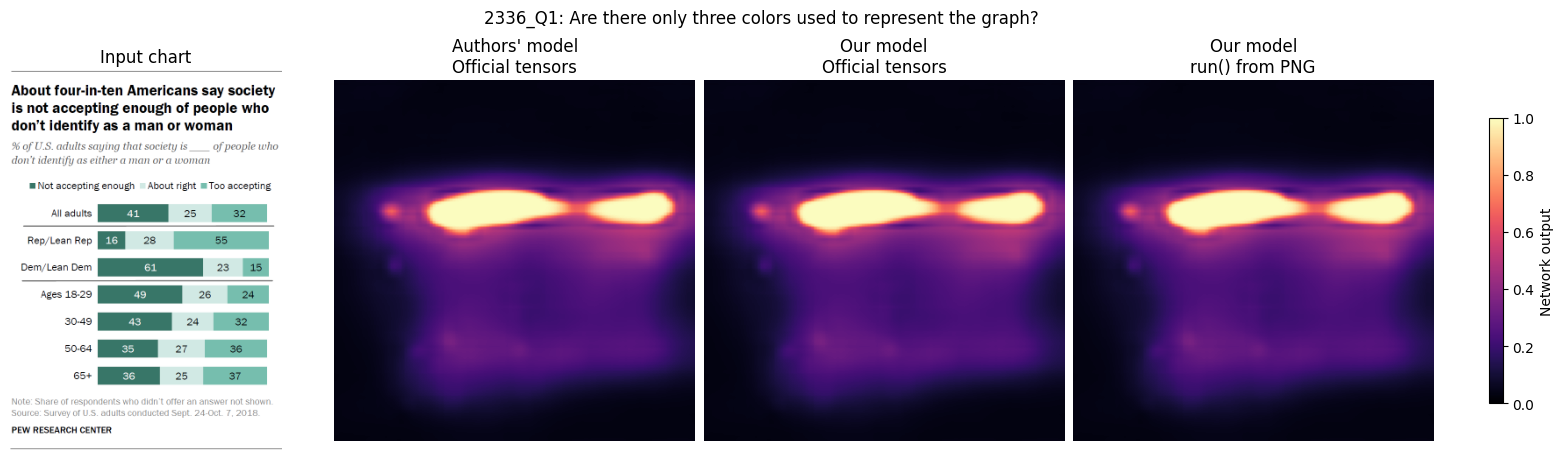

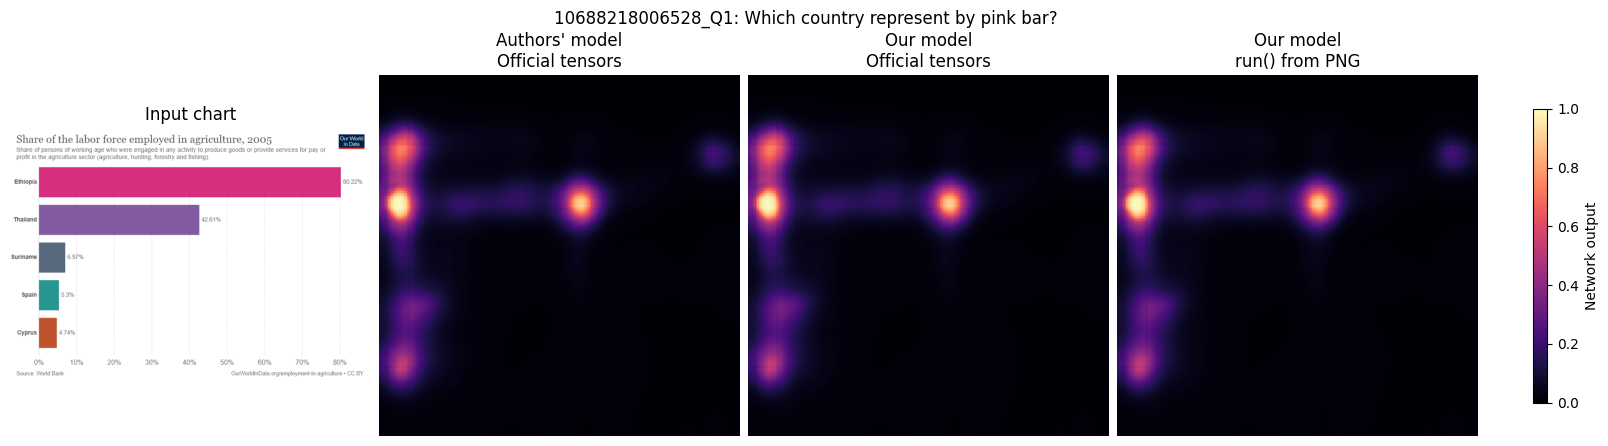

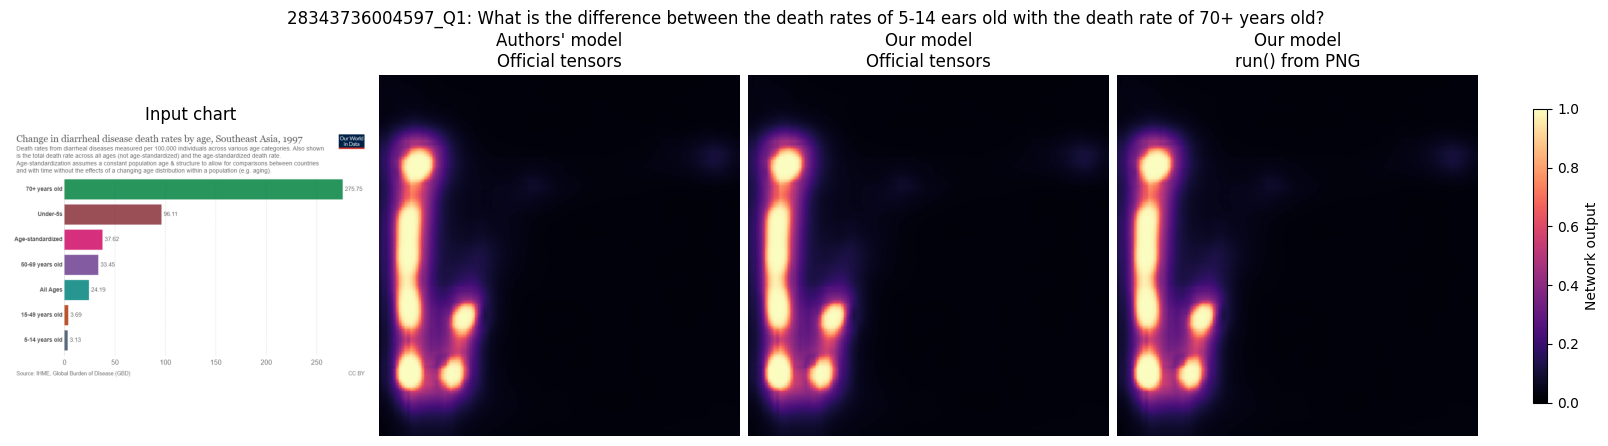

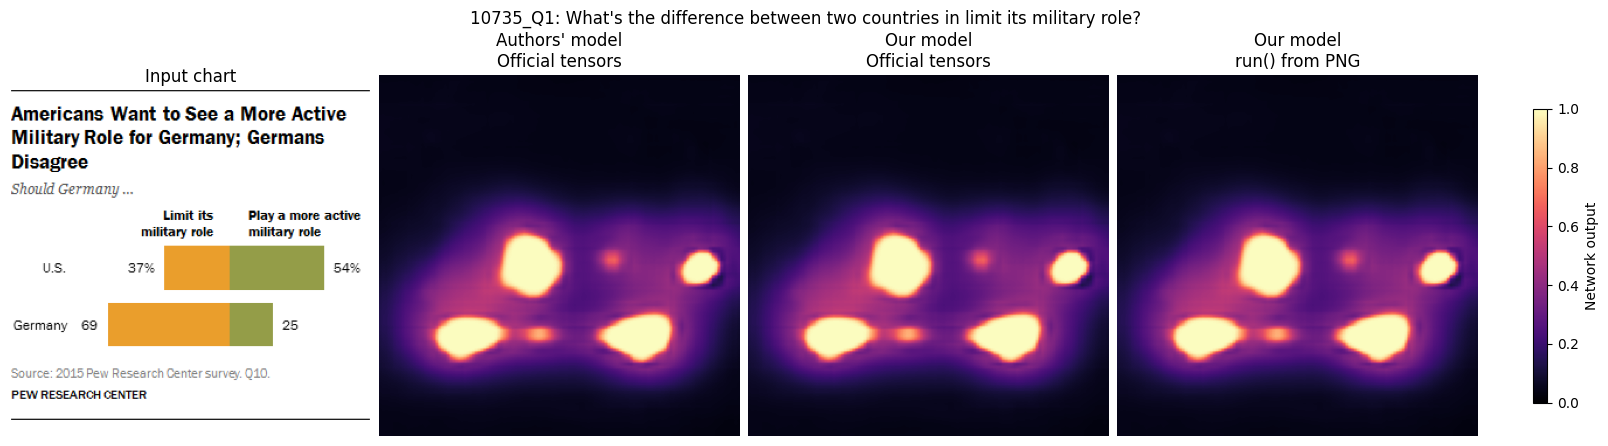

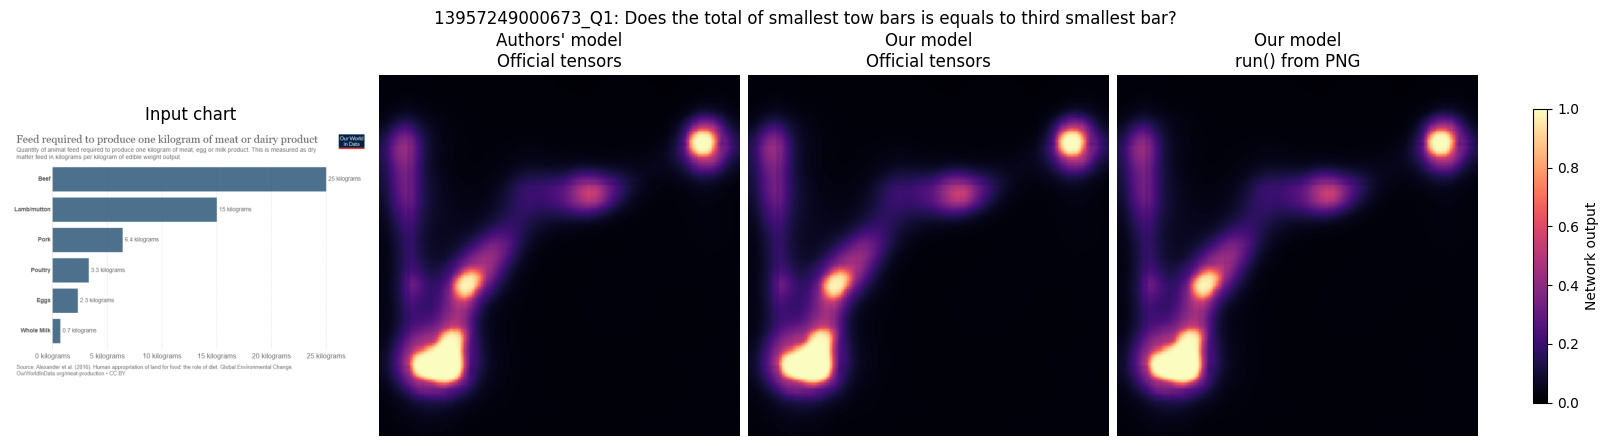

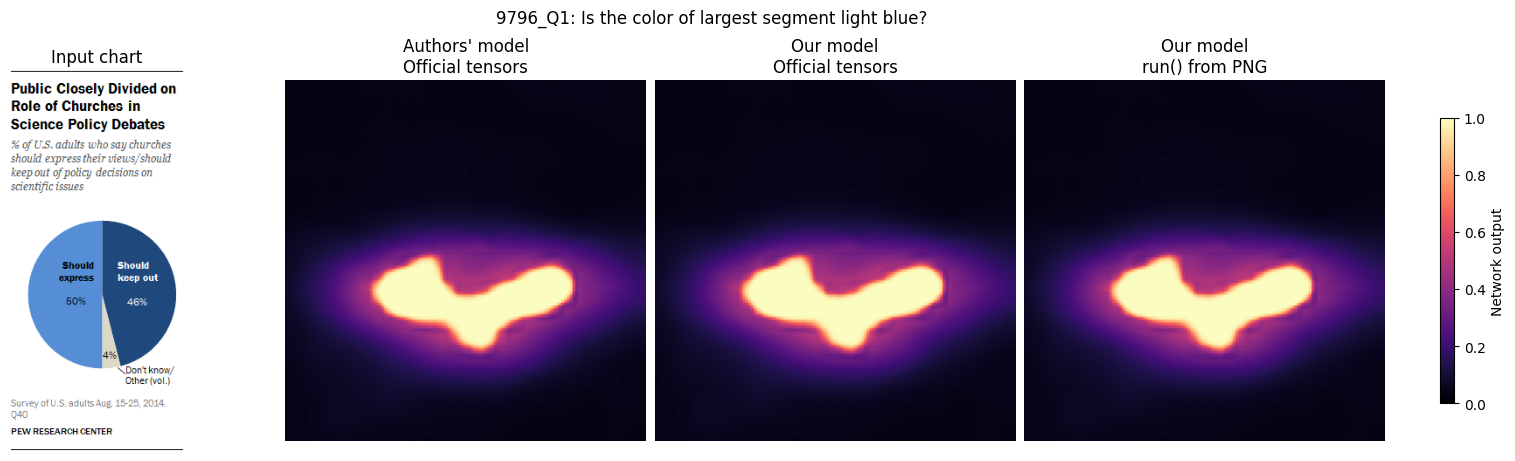

,condition_id,chart_id,question,authors_vs_ours_max_difference,tensors_vs_png_max_difference
0,1878_Q0,1878,what's the name of the biggest section in the ...,0.0,0.0
1,4353_Q1,4353,What % of voters think any voter should have t...,0.0,0.0
2,6874_Q1,6874,Is the average of green bars greater than the ...,0.0,0.0
3,06424007002454_Q1,06424007002454,How many bars are there in the chart?,0.0,0.0
4,2336_Q1,2336,Are there only three colors used to represent ...,0.0,0.0
5,10688218006528_Q1,10688218006528,Which country represent by pink bar?,0.0,0.0
6,28343736004597_Q1,28343736004597,What is the difference between the death rates...,0.0,0.0
7,10735_Q1,10735,What's the difference between two countries in...,0.0,0.0
8,13957249000673_Q1,13957249000673,Does the total of smallest tow bars is equals ...,0.0,0.0
9,9796_Q1,9796,Is the color of largest segment light blue?,0.0,0.0


In [18]:
def select_examples():
    """Choose these fixed positions in the official test, counting from 1."""
    example_numbers = [1, 4, 6, 8, 10, 12, 14, 16, 18, 20]
    selected_ids = [names[number - 1] for number in example_numbers]
    selected_charts = [chart_of[condition_id] for condition_id in selected_ids]
    assert len(set(selected_charts)) == len(selected_ids), 'Choose different charts.'
    return selected_ids


def predict_with_authors_model(batch):
    """Return the authors' raw maps as a NumPy array: [batch, height, width]."""
    image_tensors, question_tokens, _, _, _ = batch
    image_tensors = image_tensors.to(DEVICE)
    question_tokens = {key: value.to(DEVICE) for key, value in question_tokens.items()}

    with torch.no_grad():
        maps = official_model(image_tensors, question_tokens)
    return maps[:, 0].cpu().numpy()


def predict_with_our_tensors(batch):
    """Pass the official tensors through our tensor API."""
    # run_with_tensors yields one result per batch; here we provide one batch.
    maps, _ = next(predictor.run_with_tensors([batch], device=DEVICE))
    return maps[:, 0].cpu().numpy()


def predict_with_our_pngs(batch):
    """Pass PNG paths and questions to run() and keep the maps in memory."""
    batch_names = batch[4]
    inputs = []
    for name in batch_names:
        condition_id = Path(name).stem
        inputs.append({
            'condition_id': condition_id,
            'image_path': images.image(chart_of[condition_id]),
            'question': question_of[condition_id],
        })

    maps_by_id = predictor.run(inputs, batch_size=BATCH_SIZE)
    maps = []
    for item in inputs:
        maps.append(maps_by_id[item['condition_id']])
    return np.stack(maps)


def run_inference(selected_ids):
    """Run the three prediction paths and collect the selected examples."""
    predictions = []
    for batch in check_loader:
        # 1. Find the selected examples in this official batch.
        selected_examples = []
        for index, name in enumerate(batch[4]):
            condition_id = Path(name).stem
            if condition_id in selected_ids:
                selected_examples.append((index, condition_id))
        if not selected_examples:
            continue

        # 2. Predict with the authors' model and our two input APIs.
        author_maps = predict_with_authors_model(batch)
        tensor_maps = predict_with_our_tensors(batch)
        png_maps = predict_with_our_pngs(batch)

        # 3. Collect the maps to plot later.
        for index, condition_id in selected_examples:
            predictions.append({
                'condition_id': condition_id,
                'chart_id': chart_of[condition_id],
                'question': question_of[condition_id],
                'author_map': author_maps[index],
                'tensor_map': tensor_maps[index],
                'png_map': png_maps[index],
            })
        if len(predictions) == len(selected_ids):
            break

    assert len(predictions) == len(selected_ids)
    return predictions


def plot_prediction(prediction):
    """Show the chart and its three prediction maps."""
    with Image.open(images.image(prediction['chart_id'])) as source:
        chart_image = np.array(source.convert('RGB'))

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
    axes[0].imshow(chart_image)
    axes[0].set_title('Input chart')

    maps = [prediction['author_map'], prediction['tensor_map'], prediction['png_map']]
    titles = ["Authors' model\nOfficial tensors", 'Our model\nOfficial tensors',
              'Our model\nrun() from PNG']
    for ax, saliency_map, title in zip(axes[1:], maps, titles):
        heatmap = ax.imshow(saliency_map, cmap='magma', vmin=0, vmax=1)
        ax.set_title(title)
    fig.colorbar(heatmap, ax=axes[1:], label='Network output', shrink=0.75)
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f"{prediction['condition_id']}: {prediction['question']}", wrap=True)
    plt.show()
    plt.close(fig)


def show_summary(predictions):
    """Show one row per chart with the differences between prediction maps."""
    rows = []
    for prediction in predictions:
        rows.append({
            'condition_id': prediction['condition_id'],
            'chart_id': prediction['chart_id'],
            'question': prediction['question'],
            'authors_vs_ours_max_difference': float(np.abs(prediction['author_map'] - prediction['tensor_map']).max()),
            'tensors_vs_png_max_difference': float(np.abs(prediction['tensor_map'] - prediction['png_map']).max()),
        })
    summary = pd.DataFrame(rows)
    assert summary.chart_id.nunique() == len(predictions)
    display(summary)
    return summary


# 1. Select the charts and run inference.
selected_ids = select_examples()
predictions = run_inference(selected_ids)

# 2. Show the figures.
for prediction in predictions:
    plot_prediction(prediction)

# 3. Show the summary table.
preview_summary = show_summary(predictions)

## 7. Evaluate the models

We follow `official_reference/evaluation.py`:

- Keep the official test order and use batches of 16.
- Calculate KL using normalized prediction and reference saliency maps.
- Calculate CC across all pixels in each batch.
- Calculate NSS using the prediction mean and sample standard deviation across the batch, then read the values at fixation points.
- Average the 37 batch scores with equal weight: 36 batches of 16 examples and one batch of 6.

We use the same small constant, `EPS = 1e-10`, as the official script.

**Official tensors:** `run_with_tensors()` uses the prepared images and the official `padding_fn`, which pads each question to the longest question in its batch.

**Provided images:** `run(..., batch_size=16)` reads the PNG files and tokenizes the question strings internally. We pass all 582 examples in official order so each batch has the same questions and padding as the official input. Section 5 independently checks that the prepared image tensors and question tokens match.


### Prepare the evaluation batches


In [19]:
loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, collate_fn=padding_fn, num_workers=0)
assert len(loader) == 37
kl_loss = torch.nn.KLDivLoss(reduction='batchmean', log_target=True)

### Define the official scores


In [20]:
def evaluate(predictions):
    """Calculate official KL, CC and NSS, averaged over batches."""
    test_kl, test_cc, test_nss = 0, 0, 0
    for y, (img, input_ids, fix, hm, name) in predictions:
        fix = fix.to(DEVICE)
        hm = hm.to(DEVICE)

        y_sum = y.view(y.shape[0], -1).sum(1, keepdim=True)
        y_distribution = y / (y_sum[:, :, None, None] + EPS)

        hm_sum = hm.view(y.shape[0], -1).sum(1, keepdim=True)
        hm_distribution = hm / (hm_sum[:, :, None, None] + EPS)
        hm_distribution = hm_distribution + EPS
        hm_distribution = hm_distribution / (1 + EPS)

        if fix.sum() != 0:
            normal_y = (y - y.mean()) / y.std()
            nss = torch.sum(normal_y * fix) / fix.sum()
        else:
            nss = torch.Tensor([0.0]).to(DEVICE)
        kl = kl_loss(torch.log(y_distribution), torch.log(hm_distribution))

        vy = y - torch.mean(y)
        vhm = hm - torch.mean(hm)

        if (torch.sqrt(torch.sum(vy ** 2)) * torch.sqrt(torch.sum(vhm ** 2))) != 0:
            cc = torch.sum(vy * vhm) / (torch.sqrt(torch.sum(vy ** 2)) * torch.sqrt(torch.sum(vhm ** 2)))
        else:
            cc = torch.Tensor([0.0]).to(DEVICE)

        test_kl += kl.item() / len(loader)
        test_cc += cc.item() / len(loader)
        test_nss += nss.item() / len(loader)
    return {'KL': test_kl, 'CC': test_cc, 'NSS': test_nss}

### 7.1 Score our implementation on official tensors


In [21]:
metrics = evaluate(predictor.run_with_tensors(loader, device=DEVICE))
print('Our implementation:', metrics)

Our implementation: {'KL': 0.6413833015673869, 'CC': 0.6563273217227009, 'NSS': 1.7082814976975722}


### 7.2 Score the authors' model on the same official tensors


In [22]:
def official_predictions():
    for batch in loader:
        batch_images, batch_text, _, _, batch_names = batch
        with torch.no_grad():
            prediction = official_model(
                batch_images.to(DEVICE),
                {key: value.to(DEVICE) for key, value in batch_text.items()},
            )
        yield prediction, batch


official_metrics = evaluate(official_predictions())
print("Authors' model:", official_metrics)

Authors' model: {'KL': 0.6413833015673869, 'CC': 0.6563273217227009, 'NSS': 1.7082814976975722}


### 7.3 Score our PNG path using run()

Pass PNG paths and question strings to `run()`, in official order. Set `batch_size=16` to match official question padding. Keep the returned maps in memory and score them in the same official batches.


In [23]:
image_inputs = [
    {'condition_id': condition_id,
     'image_path': images.image(chart_of[condition_id]),
     'question': question_of[condition_id]}
    for condition_id in names
]
png_maps = predictor.run(image_inputs, batch_size=BATCH_SIZE)


def image_predictions():
    for batch in loader:
        batch_ids = [Path(name).stem for name in batch[4]]
        maps = [png_maps[condition_id] for condition_id in batch_ids]
        predictions = torch.from_numpy(np.stack(maps))[:, None].to(DEVICE)
        yield predictions, batch


image_metrics = evaluate(image_predictions())
print('Our run() PNG path with matching question tokens:', image_metrics)

Our run() PNG path with matching question tokens: {'KL': 0.6413833015673869, 'CC': 0.6563273217227009, 'NSS': 1.7082814976975722}


## 8. Compare models
Compare the two models on official tensors first. Their scores should match because they use the same network code, weights and inputs. The PNG result checks our image preparation using the same question tokens and padding.

Each paper difference is our score minus the published score. Lower KL is better. Higher CC and NSS are better.


,Published,Our model (tensors),Authors' model (tensors),Our model (PNG),Our minus authors,Our minus paper,Authors minus paper
Metric,,,,,,,
KL,0.532,0.641383,0.641383,0.641383,0.0,0.109383,0.109383
CC,0.674,0.656327,0.656327,0.656327,0.0,-0.017673,-0.017673
NSS,1.782,1.708281,1.708281,1.708281,0.0,-0.073719,-0.073719


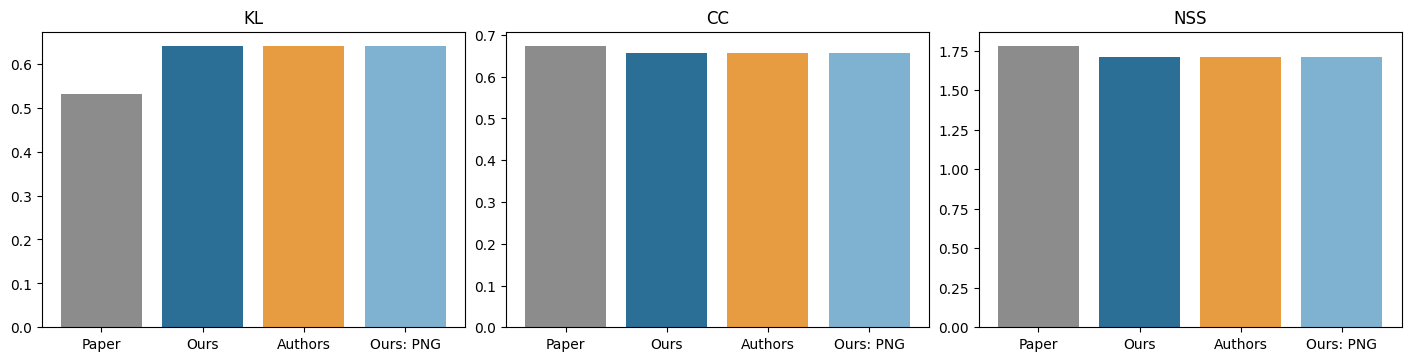

In [24]:
comparison = pd.DataFrame({
    'Published': {metric: PUBLISHED_SCORES[metric] for metric in ('KL', 'CC', 'NSS')},
    'Our model (tensors)': metrics,
    "Authors' model (tensors)": official_metrics,
    'Our model (PNG)': image_metrics,
})
comparison['Our minus authors'] = comparison['Our model (tensors)'] - comparison["Authors' model (tensors)"]
comparison['Our minus paper'] = comparison['Our model (tensors)'] - comparison['Published']
comparison['Authors minus paper'] = comparison["Authors' model (tensors)"] - comparison['Published']
comparison.index.name = 'Metric'
display(comparison.round(6))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
columns = ['Published', 'Our model (tensors)', "Authors' model (tensors)", 'Our model (PNG)']
for ax, metric in zip(axes, comparison.index):
    ax.bar(['Paper', 'Ours', 'Authors', 'Ours: PNG'], comparison.loc[metric, columns],
           color=['#8c8c8c', '#2b6f97', '#e89c41', '#7fb2d0'])
    ax.set_title(metric)
plt.show()

## 9. Check against the original evaluation script

We ran the original `official_reference/evaluation.py` main program on all **582 test examples**, using **37 batches** and a batch size of **16**.

| Metric | Original script | Notebook | Paper |
|---|---:|---:|---:|
| KL | 0.641383 | 0.641383 | 0.532 |
| CC | 0.656327 | 0.656327 | 0.674 |
| NSS | 1.708281 | 1.708281 | 1.782 |

The largest absolute difference between the original script and the notebook was **1.42 × 10⁻⁷**, consistent with floating-point precision. The table rounds both results to six decimal places.

The official source files were not changed. Runtime adapters used the local test file and model cache, loaded the checkpoint on CPU, set data-loader workers to 0 instead of 8, and disabled prediction-file and output-folder creation. The model, checkpoint, test order, batch size and metric formulas were kept the same. No prediction files were saved.

We reproduce the original script's scores within numerical precision. Our metric adaptation does not explain the difference from the paper. **The cause of the remaining difference from the published scores has not been identified.**
